# 02 · Cleaning, ALIASES, dan asal 109 label

**File:** `02_Preprocessing_dan_Audit_Label.ipynb`

Tujuan: menjalankan kembali cleaning yang sama di memori, melihat seluruh kehilangan label, dan membedakan kegagalan pemetaan dari pengecualian jumlah contoh training.

**Urutan belajar:** 01_Sumber_Data.ipynb → notebook ini → 03_Dataset_dan_Fitur.ipynb.

**Mode:** penelusuran implementasi dan pemeriksaan data di memori. Run All tidak melatih model, tidak mengunduh data, dan tidak menimpa hasil penelitian. Setiap notebook membaca inputnya sendiri; tidak memerlukan variabel dari notebook lain.

Kode ML hanya memiliki satu sumber di `KODE_ML/03_Kode/`. Sel tampilan source membaca fungsi yang benar-benar diimpor; output kode itu bukan implementasi kedua. Sel berikutnya memanggil fungsi tersebut. Data/model besar tetap di folder artefak proyek.

## Persiapan
Cari folder KODE_ML dari lokasi notebook. Import mengambil kode lokal dan menampilkan lokasi aktual supaya asal kode dapat diperiksa.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
cari = [Path.cwd(), *Path.cwd().parents]
KODE = next((p if (p / "03_Kode/runtime.py").is_file() and p.name == "KODE_ML"
             else p / "KODE_ML" for p in cari
             if (p / "03_Kode/runtime.py").is_file() and p.name == "KODE_ML"
             or (p / "KODE_ML/03_Kode/runtime.py").is_file()), None)
if KODE is None:
    raise FileNotFoundError("Buka notebook dari folder proyek atau KODE_ML.")
sys.path.insert(0, str(KODE.parent))
sys.path.insert(0, str(KODE))
from research.runtime import ROOT, read, digest
from belajar import tampilkan_sumber, tampilkan_awal
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 85)
print("Kode aktif:", KODE)


Kode aktif: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML


## Import kode cleaning

Sel ini memuat modul yang dipakai pipeline. ALIASES terlihat utuh pada output konstanta; daftar ini bukan daftar kelas model.

In [2]:
from research import preprocessing as prep, source_identity as identity
tampilkan_awal(prep)
print('Jumlah alias manual:', len(prep.ALIASES))

**Import dan konstanta aktual:** `KODE_ML/03_Kode/preprocessing.py`. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
"""Cleaning lima sumber dari snapshot lokal; anggota kohor/split tetap beku."""
from collections import Counter, defaultdict
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from .runtime import ROOT, SOURCE_ROOT, read, digest
from .source_identity import _attach_smiles, _attach_sigma, _cas_bridge, _truthy, normalize
from .splits import POLICY
from .dataset import DATASET, verify, encode_frozen_records
CONFIG = SOURCE_ROOT / "config/sources.json"
REQUIRED_SOURCES = {"goodscents", "ifra", "leffingwell", "arctander", "sigma"}
IFRA_COLUMNS = ["Descriptor 1", "Descriptor 2", "Descriptor 3"]
# Only explicit lexical equivalents; no fuzzy guesses or taste-to-odor conversion.
ALIASES = {
    "fruit": "fruity", "fruits": "fruity", "flower": "floral", "flowers": "floral",
    "floral notes": "floral", "wood": "woody", "woods": "woody", "herb": "herbal",
    "herbaceous": "herbal", "green notes": "green", "citrus notes": "citrus",
    "spice": "spicy", "spicy notes": "spicy", "sweet notes": "sweet",
    "cream": "creamy", "butter": "buttery", "nut": "nutty", "smoke": "smoky",
    "smokey": "smoky", "earth": "earthy", "mint": "minty", "oil": "oily",
    "musk": "musk like", "animal": "animal like", "animalic": "animal like",
    "jasmine": "jasmin", "savory": "savoury", "tropical": "tropical fruit",
    "sulphurous": "sulfurous", "balsam": "balsamic", "powder": "powdery",
}


```

Jumlah alias manual: 31


## normalize

Lowercase, tanda baca menjadi spasi, spasi dirapikan. Tidak ada pencarian kemiripan ejaan. Misalnya huruf besar dapat disamakan, tetapi ejaan berbeda belum tentu cocok.

In [3]:
tampilkan_sumber(identity.normalize)

**Source aktual:** `KODE_ML/03_Kode/source_identity.py`, baris 32–36. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `36fb057eb35996f5a0f386712d6ce07896cb4ff9ef3675ead78325e8fecbccc6`.

```python
def normalize(token: str) -> str:
    """Lowercase, strip punctuation, collapse whitespace."""
    t = str(token).strip().lower()
    t = _NON_ALNUM.sub(" ", t)
    return _WS.sub(" ", t).strip()

```

## _truthy

Kolom one-hot Leffingwell/Sigma dianggap positif hanya untuk 1, 1.0, atau true.

In [4]:
tampilkan_sumber(identity._truthy)

**Source aktual:** `KODE_ML/03_Kode/source_identity.py`, baris 74–75. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `36fb057eb35996f5a0f386712d6ce07896cb4ff9ef3675ead78325e8fecbccc6`.

```python
def _truthy(value):
    return str(value).strip().lower() in {"1", "1.0", "true"}

```

## taxonomy_from_ifra

Daftar kandidat diambil otomatis dari Descriptor 1–3 IFRA, dinormalisasi, dihapus duplikatnya, lalu diurutkan. Daftar ini mendahului pencocokan karena menjadi kamus tujuan.

In [5]:
tampilkan_sumber(prep.taxonomy_from_ifra)

**Source aktual:** `KODE_ML/03_Kode/preprocessing.py`, baris 60–64. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
def taxonomy_from_ifra(behavior):
    if not set(IFRA_COLUMNS).issubset(behavior):
        raise ValueError("IFRA must provide its three descriptor columns.")
    return sorted({normalize(value) for value in behavior[IFRA_COLUMNS].stack()
                   if isinstance(value, str) and normalize(value)})

```

## tokens_for

IFRA memakai tiga kolom teks, GoodScents/Arctander memecah tanda ;, Leffingwell/Sigma membaca nama kolom yang nilainya positif. Nilai biner aneh menghasilkan error.

In [6]:
tampilkan_sumber(prep.tokens_for)

**Source aktual:** `KODE_ML/03_Kode/preprocessing.py`, baris 82–94. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
def tokens_for(source, row, behavior_columns):
    if source == "ifra":
        return [row.get(name) for name in IFRA_COLUMNS]
    if source in ("leffingwell", "sigma"):
        columns = [c for c in behavior_columns if normalize(c) not in {"stimulus", "descriptors", "labels", "cid", "cas"}]
        invalid = [(c, row[c]) for c in columns if pd.notna(row[c]) and str(row[c]).strip().lower()
                   not in {"", "0", "0.0", "1", "1.0", "false", "true"}]
        if invalid:
            raise ValueError(f"Invalid binary behavior values: {invalid[:3]}")
        return [c for c in columns if _truthy(row[c])]
    column = "Labels" if source == "arctander" else "Descriptors"
    value = row.get(column)
    return value.split(";") if isinstance(value, str) else []

```

## map_labels

Urutan keputusan: normalisasi → exact match terhadap taksonomi → alias manual bila exact tidak ada → catat unmatched. Exact memiliki prioritas di atas alias. Set menghindari label ganda dalam satu baris.

In [7]:
tampilkan_sumber(prep.map_labels)

**Source aktual:** `KODE_ML/03_Kode/preprocessing.py`, baris 67–79. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
def map_labels(tokens, taxonomy, source, unmapped, mappings):
    accepted = set()
    for token in tokens:
        if not isinstance(token, str) or not token.strip():
            continue
        term = normalize(token)
        mapped = term if term in taxonomy else ALIASES.get(term)
        if mapped in taxonomy:
            accepted.add(mapped)
            mappings[(source, term, mapped, "exact" if term == mapped else "alias")] += 1
        else:
            unmapped[(source, term)] += 1
    return accepted

```

## merge_sources

Urutan asli: identitas → validitas SMILES → satu komponen → baca token → petakan label → gabungkan label dan sumber berdasarkan canonical SMILES. Baris tanpa label yang cocok ditolak; baris dengan sebagian label cocok tetap dipakai. Semua kegagalan dicatat.

| Blok dalam fungsi | Yang terjadi dan mengapa |
|---|---|
| taxonomy, frames, cas_map | Siapkan kamus IFRA dan sambungan identitas; belum memilih 109 kelas. |
| counts dan base | Buat penghitung serta identitas source/baris agar setiap penolakan dapat ditelusuri. |
| reason + continue pertama | Hentikan baris yang identitas/SMILES/komponennya tidak memenuhi syarat, sebelum label dibaca. |
| tokens_for + except | Baca bentuk anotasi tiap sumber; nilai biner tidak sah dicatat sebagai invalid_behavior. |
| map_labels + if not labels | Bedakan label kosong dengan semua istilah gagal dipetakan. Kedua kasus tidak dipaksa menjadi negatif. |
| merged[canonical].update(labels) | Satukan label yang diterima dari molekul identik; set mencegah duplikasi label, bukan menghapus molekul yang labelnya sama. |
| origins dan provenance | Simpan sumber molekul dan jejak baris asli. |
| rekonsiliasi counts | Accepted + seluruh alasan reject wajib sama dengan jumlah baris sumber. |
| records, unmap, mapped | Urutkan molekul secara deterministik dan kembalikan tabel hasil serta audit istilah. |


In [8]:
tampilkan_sumber(prep.merge_sources)

**Source aktual:** `KODE_ML/03_Kode/preprocessing.py`, baris 97–164. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
def merge_sources(tables, config):
    RDLogger.DisableLog("rdApp.warning")
    taxonomy = taxonomy_from_ifra(tables["ifra_behavior"])
    tax = set(taxonomy)
    frames = {}
    for source in config["sources"]:
        if source != "sigma":
            frames[source] = _attach_smiles(tables[f"{source}_behavior"],
                                           tables[f"{source}_stimuli"], tables[f"{source}_molecules"])
    cas_map, ambiguous = _cas_bridge(tables, frames)
    frames["sigma"], sigma_exclusions = _attach_sigma(tables["sigma_behavior"], tables["sigma_stimuli"], cas_map)
    merged, origins = defaultdict(set), defaultdict(set)
    audit, rejected, provenance = {}, [], []
    unmapped, mappings = Counter(), Counter()
    for source in config["sources"]:
        frame = frames[source]
        expected = IFRA_COLUMNS if source == "ifra" else ["Labels"] if source == "arctander" else ["Descriptors"] if source == "goodscents" else []
        if not set(expected).issubset(frame):
            raise ValueError(f"Unexpected behavior schema: {source}")
        counts = {"rows": len(frame), "missing_identity": 0, "invalid_smiles": 0,
                  "multifragment": 0, "empty_labels": 0, "unmapped_labels": 0,
                  "invalid_behavior": 0, "accepted": 0}
        for row_number, (_, row) in enumerate(frame.iterrows()):
            base = {"source": source, "row": row_number, "stimulus": str(row["Stimulus"])}
            smiles = row["__smiles__"]
            reason = None
            if not isinstance(smiles, str) or not smiles.strip():
                reason = "missing_identity"
            else:
                mol = Chem.MolFromSmiles(smiles)
                if mol is None or mol.GetNumAtoms() == 0:
                    reason = "invalid_smiles"
                elif len(Chem.GetMolFrags(mol)) != 1:
                    reason = "multifragment"
            if reason:
                counts[reason] += 1
                rejected.append(dict(base, reason=reason))
                continue
            try:
                tokens = tokens_for(source, row, tables[f"{source}_behavior"].columns)
            except ValueError as exc:
                counts["invalid_behavior"] += 1
                rejected.append(dict(base, reason="invalid_behavior", detail=str(exc)))
                continue
            labels = map_labels(tokens, tax, source, unmapped, mappings)
            if not labels:
                reason = "empty_labels" if not any(isinstance(t,str) and t.strip() for t in tokens) else "unmapped_labels"
                counts[reason] += 1
                rejected.append(dict(base, reason=reason))
                continue
            canonical = Chem.MolToSmiles(mol, isomericSmiles=True)
            merged[canonical].update(labels)
            origins[canonical].add(source)
            provenance.append(dict(base, smiles=canonical, labels=sorted(labels)))
            counts["accepted"] += 1
        if sum(value for key, value in counts.items() if key != "rows") != counts["rows"]:
            raise AssertionError("Source attrition does not reconcile.")
        if counts["accepted"] == 0:
            raise ValueError(f"No usable records from {source}; inspect its schema and identity mapping.")
        audit[source] = counts
    records = pd.DataFrame([{"source_row": i, "smiles": s, "labels": sorted(merged[s]),
                             "sources": sorted(origins[s])} for i,s in enumerate(sorted(merged))])
    unmap = pd.DataFrame([{"source": s,"descriptor": t,"count":n} for (s,t),n in unmapped.most_common()],
                        columns=["source","descriptor","count"])
    mapped = pd.DataFrame([{"source":s,"raw_descriptor":a,"label":b,"method":m,"count":n}
                           for (s,a,b,m),n in sorted(mappings.items())])
    return records, taxonomy, {"sources":audit,"ambiguous_cas":ambiguous,
                              "sigma_identity_exclusions":sigma_exclusions}, rejected, provenance, unmap, mapped

```

## review_frozen_preprocessing

Menjalankan cleaning yang sama, lalu membandingkan records dan matriks target dengan artefak beku. Ini audit, bukan menulis ulang data atau memilih konfigurasi baru.

In [9]:
tampilkan_sumber(prep.review_frozen_preprocessing)

**Source aktual:** `KODE_ML/03_Kode/preprocessing.py`, baris 166–176. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `91aaeca7a9a9b6bb0cfae5349168c1205f62fb588496961c58193be96fb7ef14`.

```python
def review_frozen_preprocessing():
    """Ulangi cleaning di memori untuk audit; tidak membuat dataset atau split baru."""
    config = load_config()
    tables, sources = load_sources(config)
    records, taxonomy, audit, rejected, provenance, unmapped, mappings = merge_sources(tables, config)
    checked = verify()
    target, labels, split = encode_frozen_records(records, verified=checked)
    return {"records": records, "target": target, "labels": labels, "split": split,
            "taxonomy": taxonomy, "audit": audit, "rejected": rejected,
            "provenance": provenance, "unmapped": unmapped, "mappings": mappings,
            "sources": sources}

```

## Kode pemeriksa label tambahan

`audit_labels.py` berada dalam folder ini. Ia memanggil fungsi produksi yang sudah dijelaskan, lalu membuat jejak setiap token.

| Blok fungsi | Input → proses → output |
|---|---|
| Baca dan replay | Snapshot → merge_sources + encode_frozen_records → records dan target yang wajib identik |
| events | Token tiap baris → map_labels yang sama → ejaan asli, hasil normalisasi, tujuan, dan alasan pemakaian |
| reached | Pisahkan baris yang benar-benar mencapai mapper dari baris yang ditolak sebelumnya |
| Rekonsiliasi | Jumlahkan token → cocokkan penghitung produksi dan CSV historis; perbedaan memicu error |
| Seleksi target | Seluruh 184 label + indeks train → syarat dukungan asli → urutan 109 target |
| aliases | Tinjau 31 aturan manual, apakah tujuan tersedia dan aturan benar-benar terpakai |
| Tabel akhir | Kelompokkan temuan per istilah/per sumber; tidak memperbaiki label otomatis |

Kode diagnostik ini baru. Kesetaraan yang diuji adalah hasil pemetaan dan targetnya dengan implementasi asli, bukan klaim bahwa kode audit pernah digunakan untuk training.

In [10]:
import audit_labels
tampilkan_sumber(audit_labels.audit_labels)

**Source aktual:** `KODE_ML/audit_labels.py`, baris 16–167. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `ad7f3aba393868af10b2a07ac4d43889c04caec1a5b561405004b29fe0dd7c86`.

```python
def audit_labels():
    """Kembalikan tabel audit di memori; semua hitungan memakai kode produksi."""
    config = load_config()
    tables, snapshot = load_sources(config)
    records, taxonomy, attrition, rejected, provenance, unmapped, mappings = merge_sources(tables, config)
    verified = verify()
    target, labels, split = encode_frozen_records(records, verified=verified)
    tax, retained = set(taxonomy), set(labels)
    rejected_by_row = {(r["source"], r["row"]): r["reason"] for r in rejected}

    # Bagian ini mengamati semua token, termasuk baris yang tidak mencapai mapper.
    events, raw_rows = [], []
    for source in config["sources"]:
        behavior = tables[f"{source}_behavior"]
        for row_number, (_, row) in enumerate(behavior.iterrows()):
            rejection = rejected_by_row.get((source, row_number), "accepted")
            try:
                tokens = tokens_for(source, row, behavior.columns)
            except ValueError:
                raw_rows.append({"source": source, "row": row_number, "reason": "invalid_behavior"})
                continue
            usable_tokens = [t for t in tokens if isinstance(t, str) and t.strip()]
            raw_rows.append({"source": source, "row": row_number,
                             "reason": rejection, "raw_token_count": len(usable_tokens)})
            for token in usable_tokens:
                normal = normalize(token)
                accepted, not_mapped = Counter(), Counter()
                found = map_labels([token], tax, source, not_mapped, accepted)
                mapped = next(iter(found)) if found else ""
                method = "exact" if mapped == normal and mapped else "alias" if mapped else "unmapped"
                reached = rejection not in {"missing_identity", "invalid_smiles", "multifragment", "invalid_behavior"}
                if not reached:
                    reason = "row_" + rejection
                elif not mapped:
                    reason = "not_in_taxonomy_or_valid_alias"
                elif mapped not in retained:
                    reason = "mapped_but_below_train_support"
                else:
                    reason = "retained_label"
                events.append({"source": source, "row": row_number,
                               "raw_token": token, "normalized_token": normal,
                               "normalization_changed": token != normal,
                               "mapped_label": mapped, "mapping_method": method,
                               "reached_production_mapper": reached,
                               "row_outcome": rejection, "final_use_reason": reason})
    events = pd.DataFrame(events)
    reached = events[events.reached_production_mapper].copy()
    raw_rows = pd.DataFrame(raw_rows)
    # Reconcile individual observed tokens against the historical mapper counters.
    actual_unmapped = reached[reached.mapping_method.eq("unmapped")].groupby(
        ["source", "normalized_token"]).size().to_dict()
    expected_unmapped = {(r.source, r.descriptor): int(r.count) for r in unmapped.itertuples()}
    if actual_unmapped != expected_unmapped:
        raise AssertionError("Token audit does not reconcile with merge_sources unmapped counters.")
    actual_mapped = reached[reached.mapping_method.ne("unmapped")].groupby(
        ["source", "normalized_token", "mapped_label", "mapping_method"]).size().to_dict()
    expected_mapped = {(r.source, r.raw_descriptor, r.label, r.method): int(r.count) for r in mappings.itertuples()}
    if actual_mapped != expected_mapped:
        raise AssertionError("Token audit does not reconcile with merge_sources mapped counters.")
    stored_unmapped = pd.read_csv(DATASET / "unmapped_descriptors.csv")
    stored_mappings = pd.read_csv(DATASET / "label_mappings.csv")
    pd.testing.assert_frame_equal(unmapped.reset_index(drop=True), stored_unmapped, check_dtype=False)
    pd.testing.assert_frame_equal(mappings.reset_index(drop=True), stored_mappings, check_dtype=False)

    # Ulangi aturan seleksi asli, tetapi gunakan indeks train yang sudah dibekukan.
    all_target = np.asarray([[int(name in row) for name in taxonomy]
                             for row in records.labels], dtype=np.uint8)
    train_positive = all_target[split["train"]].sum(axis=0)
    train_negative = len(split["train"]) - train_positive
    selected = (train_positive >= config["labels"]["min_train_positive"]) & (train_negative >= 2)
    selection = pd.DataFrame({"label": taxonomy, "train_positive": train_positive,
                              "train_negative": train_negative, "selected": selected,
                              "selection_reason": np.where(selected, "retained",
                                  np.where(train_positive < config["labels"]["min_train_positive"],
                                           "train_positive_below_30", "train_negative_below_2"))})
    if selection.loc[selection.selected, "label"].tolist() != labels:
        raise AssertionError("Recomputed label selection differs from frozen 109 labels.")
    stored_selection = pd.read_csv(DATASET / "label_selection.csv")
    pd.testing.assert_frame_equal(selection[list(stored_selection.columns)], stored_selection, check_dtype=False)
    if not np.array_equal(all_target[:, selected], target):
        raise AssertionError("Selected targets differ from the frozen targets.")

    alias_rows = []
    for alias, destination in ALIASES.items():
        observed = reached[reached.normalized_token.eq(alias)]
        alias_rows.append({"alias": alias, "destination": destination,
                           "destination_in_taxonomy": destination in tax,
                           "alias_itself_in_taxonomy": alias in tax,
                           "observed_tokens_at_mapper": len(observed),
                           "tokens_using_alias": int(observed.mapping_method.eq("alias").sum()),
                           "status": "exact_takes_priority" if alias in tax else
                                     "destination_outside_taxonomy" if destination not in tax else
                                     "used" if len(observed) else "not_observed"})
    aliases = pd.DataFrame(alias_rows)
    token_inventory = events.groupby(
        ["source", "raw_token", "normalized_token", "mapped_label", "mapping_method",
         "reached_production_mapper", "row_outcome", "final_use_reason"], dropna=False
    ).size().rename("count").reset_index().sort_values(["count", "source"], ascending=[False, True])
    unmatched_inventory = reached[reached.mapping_method.eq("unmapped")].groupby(
        ["normalized_token"], dropna=False).agg(
            token_occurrences=("row", "size"), sources=("source", lambda values: ";".join(sorted(set(values)))),
            raw_spellings=("raw_token", lambda values: json.dumps(sorted(set(values)), ensure_ascii=False))
        ).reset_index().sort_values("token_occurrences", ascending=False)
    per_source = []
    for source in config["sources"]:
        raw = events[events.source.eq(source)]
        used = reached[reached.source.eq(source)]
        accepted_rows_with_unknown = used[used.mapping_method.eq("unmapped") & used.row_outcome.eq("accepted")].row.nunique()
        per_source.append({"source": source, **attrition["sources"][source],
                           "raw_token_occurrences": len(raw),
                           "raw_normalized_terms": raw.normalized_token.nunique(),
                           "mapper_token_occurrences": len(used),
                           "exact_tokens": int(used.mapping_method.eq("exact").sum()),
                           "alias_tokens": int(used.mapping_method.eq("alias").sum()),
                           "unmapped_tokens": int(used.mapping_method.eq("unmapped").sum()),
                           "unmapped_terms": used[used.mapping_method.eq("unmapped")].normalized_token.nunique(),
                           "accepted_rows_with_unmapped_tokens": int(accepted_rows_with_unknown)})
    per_source = pd.DataFrame(per_source)
    summary = {
        "snapshot_revision": config["revision"], "sources": list(config["sources"]),
        "raw_behavior_rows": int(sum(len(tables[f"{s}_behavior"]) for s in config["sources"])),
        "accepted_source_rows_before_merge": int(sum(v["accepted"] for v in attrition["sources"].values())),
        "rejected_source_rows": len(rejected), "unique_molecules": len(records),
        "taxonomy_terms_from_ifra": len(taxonomy), "manual_alias_entries": len(ALIASES),
        "selected_labels": len(labels), "excluded_taxonomy_terms": int((~selected).sum()),
        "min_train_positive": config["labels"]["min_train_positive"], "min_train_negative": 2,
        "all_zero_retained_target_rows_train": int((target[split["train"]].sum(axis=1) == 0).sum()),
        "all_zero_retained_target_rows_test": int((target[split["test"]].sum(axis=1) == 0).sum()),
        "raw_token_occurrences_all_rows": len(events),
        "normalized_terms_all_rows": int(events.normalized_token.nunique()),
        "tokens_reaching_mapper": len(reached),
        "normalized_terms_reaching_mapper": int(reached.normalized_token.nunique()),
        "exact_token_occurrences": int(reached.mapping_method.eq("exact").sum()),
        "alias_token_occurrences": int(reached.mapping_method.eq("alias").sum()),
        "unmapped_token_occurrences": int(reached.mapping_method.eq("unmapped").sum()),
        "unmapped_normalized_terms": len(unmatched_inventory),
        "mapped_normalized_terms": int(reached[reached.mapping_method.ne("unmapped")].normalized_token.nunique()),
        "mapped_distinct_taxonomy_labels": int(reached.loc[reached.mapping_method.ne("unmapped"), "mapped_label"].nunique()),
        "normalization_changed_token_occurrences": int(reached.normalization_changed.sum()),
        "retained_rows_with_unmapped_tokens": int(reached[reached.mapping_method.eq("unmapped") & reached.row_outcome.eq("accepted")][["source", "row"]].drop_duplicates().shape[0]),
        "selection_equals_frozen": True, "targets_equal_frozen": True,
        "mapping_counters_equal_original": True,
        "mapping_tables_equal_saved": True,
        "unmapped_audit_scope": "Only tokens on valid single-molecule rows reach the original mapper. All-row token audit is additional diagnostics, not training data.",
        "semantic_accuracy_validated": False,
    }
    return {"summary": summary, "per_source": per_source, "taxonomy_selection": selection,
            "aliases": aliases, "token_inventory": token_inventory,
            "unmatched_terms": unmatched_inventory, "mappings": mappings,
            "unmapped_by_source": unmapped, "rejected_rows": pd.DataFrame(rejected),
            "raw_row_status": raw_rows, "records": records, "target": target,
            "labels": labels, "taxonomy": taxonomy, "snapshot": snapshot}

```

## Jalankan audit menyeluruh

Input: snapshot lima sumber dan split training beku. Output: audit label, counter sumber, daftar unmatched dan seleksi kandidat. Fungsi audit ini observasi tambahan; ia tidak menambahkan fuzzy matching atau mengubah ALIASES.

In [11]:
import audit_labels
audit = audit_labels.audit_labels()
display(audit['summary'])

{'snapshot_revision': '8054ea98ed675005ec10e67359902f500e4911b0',
 'sources': ['goodscents', 'ifra', 'leffingwell', 'arctander', 'sigma'],
 'raw_behavior_rows': 13337,
 'accepted_source_rows_before_merge': 11777,
 'rejected_source_rows': 1560,
 'unique_molecules': 6686,
 'taxonomy_terms_from_ifra': 184,
 'manual_alias_entries': 31,
 'selected_labels': 109,
 'excluded_taxonomy_terms': 75,
 'min_train_positive': 30,
 'min_train_negative': 2,
 'all_zero_retained_target_rows_train': 11,
 'all_zero_retained_target_rows_test': 4,
 'raw_token_occurrences_all_rows': 47406,
 'normalized_terms_all_rows': 704,
 'tokens_reaching_mapper': 45689,
 'normalized_terms_reaching_mapper': 699,
 'exact_token_occurrences': 37940,
 'alias_token_occurrences': 1255,
 'unmapped_token_occurrences': 6494,
 'unmapped_normalized_terms': 498,
 'mapped_normalized_terms': 201,
 'mapped_distinct_taxonomy_labels': 184,
 'normalization_changed_token_occurrences': 3433,
 'retained_rows_with_unmapped_tokens': 3898,
 'selec

## Buktikan asal angka 109

Tabel ini berisi 184 istilah yang terbaca dari IFRA; kolom selected menunjukkan hasil syarat jumlah contoh training. Tidak ada top-N atau daftar 109 label buatan tangan.

In [12]:
selection = audit['taxonomy_selection']
display(selection.groupby('selected').agg(jumlah=('label','size'),min_positif=('train_positive','min'),max_positif=('train_positive','max')))
with pd.option_context('display.max_rows',200):
    display(selection)
assert selection.loc[selection.selected,'label'].tolist() == audit['labels']

,jumlah,min_positif,max_positif
selected,,,
False,75,1,28
True,109,32,1987


,label,train_positive,train_negative,selected,selection_reason
0,acidic,36,5317,True,retained
1,aldehydic,152,5201,True,retained
2,almond,86,5267,True,retained
3,amber,74,5279,True,retained
4,animal like,156,5197,True,retained
5,anisic,83,5270,True,retained
6,apple,308,5045,True,retained
7,apricot,102,5251,True,retained
8,aromatic,78,5275,True,retained
9,artemisia,1,5352,False,train_positive_below_30


**184 → 109** merupakan hasil aturan atas data training. **75 lainnya berhasil dikenali**, tetapi hanya mempunyai 1–28 contoh positif di train, sehingga tidak masuk target penelitian. Daftar 109 kemudian disimpan agar urutan target dan model tidak berubah.

## Lihat semua alias manual

Input: ALIASES yang benar-benar dipakai map_labels. Output: setiap aturan, tujuan, ketersediaan tujuan, dan frekuensi pemakaiannya. Daftar manual diperlukan untuk variasi istilah yang tidak sama persis, bukan untuk menetapkan seluruh kelas.

In [13]:
with pd.option_context('display.max_rows',40):
    display(audit['aliases'])

,alias,destination,destination_in_taxonomy,alias_itself_in_taxonomy,observed_tokens_at_mapper,tokens_using_alias,status
0,fruit,fruity,True,False,3,3,used
1,fruits,fruity,True,False,0,0,not_observed
2,flower,floral,True,False,7,7,used
3,flowers,floral,True,False,1,1,used
4,floral notes,floral,True,False,0,0,not_observed
5,wood,woody,True,False,1,1,used
6,woods,woody,True,False,0,0,not_observed
7,herb,herbal,True,False,1,1,used
8,herbaceous,herbal,True,False,67,67,used
9,green notes,green,True,False,0,0,not_observed


Terdapat **31 aturan manual**, **17 terpakai**, dan 14 tidak teramati pada token yang mencapai mapper. Ini membuktikan pemakaian aturan, belum membuktikan seluruh pasangan alias benar secara makna.

## Rekonsiliasi jumlah baris dan token

Baris sumber berbeda dari molekul unik; token berbeda dari label unik. Tabel ini menjaga penyebutnya jelas. Tabel penuh disimpan di 06_Audit_Label/per_source.csv.

,source,rows,missing_identity,invalid_smiles,multifragment,empty_labels,unmapped_labels,invalid_behavior,accepted,raw_token_occurrences,raw_normalized_terms,mapper_token_occurrences,exact_tokens,alias_tokens,unmapped_tokens,unmapped_terms,accepted_rows_with_unmapped_tokens
0,goodscents,4626,0,0,183,4,335,0,4104,20448,666,20187,15542,528,4117,479,2128
1,ifra,1146,0,0,28,0,0,0,1118,3438,184,3354,3354,0,0,0,0
2,leffingwell,3522,0,0,0,0,114,0,3408,12869,113,12869,10892,516,1461,26,1055
3,arctander,3102,278,0,102,209,73,0,2440,8021,77,7180,6436,73,671,15,531
4,sigma,941,204,0,0,0,30,0,707,2630,117,2099,1716,138,245,32,184


,status,kemunculan_token
0,Exact setelah normalisasi,37940
1,Alias manual,1255
2,Tidak terpetakan,6494


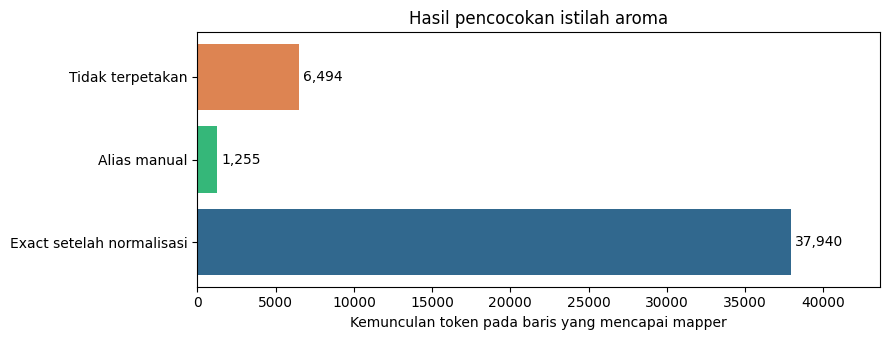

In [14]:
display(audit['per_source'])
s = audit['summary']
assert s['exact_token_occurrences'] + s['alias_token_occurrences'] + s['unmapped_token_occurrences'] == s['tokens_reaching_mapper']
assert s['accepted_source_rows_before_merge'] + s['rejected_source_rows'] == s['raw_behavior_rows']
flow = pd.DataFrame({'status':['Exact setelah normalisasi','Alias manual','Tidak terpetakan'],
                    'kemunculan_token':[s['exact_token_occurrences'],s['alias_token_occurrences'],s['unmapped_token_occurrences']]})
display(flow)
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(flow['status'],flow['kemunculan_token'],color=['#31688e','#35b779','#dd8452'])
ax.set(xlabel='Kemunculan token pada baris yang mencapai mapper',title='Hasil pencocokan istilah aroma')
for i,v in enumerate(flow['kemunculan_token']):ax.text(v+250,i,f'{v:,}',va='center')
ax.set_xlim(0,flow['kemunculan_token'].max()*1.15)
fig.tight_layout();plt.show()

**6.494 dari 45.689 kemunculan token (sekitar 14,2%) belum terpetakan.** Ini bukan persentase molekul yang dibuang. Sebanyak 3.898 baris yang diterima masih memiliki sebagian token tidak terpetakan.

## Label gagal: tampilkan dan telusuri seluruhnya

Preview menampilkan 25 istilah terbanyak; tabel audit di folder ini berisi seluruh 498 istilah. Tidak ada label baru atau kategori pengganti yang ditambahkan.

In [15]:
unmatched = audit['unmatched_terms']
display(unmatched.head(25))
display(audit['rejected_rows'].groupby(['source','reason']).size().rename('baris').to_frame())
display(audit['token_inventory'].query("final_use_reason == 'mapped_but_below_train_support'")
        .groupby('mapped_label')['count'].sum().sort_values(ascending=False).head(10).to_frame())
print('Seluruh unmatched:', KODE/'06_Audit_Label/unmatched_terms.csv')
print('Seluruh ejaan asli dan keputusan:', KODE/'06_Audit_Label/token_inventory.csv')

,normalized_token,token_occurrences,sources,raw_spellings
292,meaty,430,goodscents;leffingwell;sigma,"[""meaty""]"
488,winey,407,arctander;goodscents;leffingwell,"[""winey""]"
94,caramellic,292,goodscents;leffingwell,"[""caramellic""]"
329,odorless,183,goodscents;leffingwell,"[""odorless""]"
87,camphoreous,180,goodscents;leffingwell,"[""camphoreous""]"
14,alliaceous,144,goodscents;leffingwell;sigma,"[""alliaceous""]"
147,cognac,123,goodscents;leffingwell,"[""cognac""]"
11,alcoholic,118,goodscents;leffingwell,"[""alcoholic""]"
310,musky,106,arctander;goodscents,"[""musky""]"
201,fishy,104,goodscents;leffingwell;sigma,"[""fishy""]"


baris
source      reason                 
arctander   empty_labels        209
            missing_identity    278
            multifragment       102
            unmapped_labels      73
goodscents  empty_labels          4
            multifragment       183
            unmapped_labels     335
ifra        multifragment        28
leffingwell unmapped_labels     114
sigma       missing_identity    204
            unmapped_labels      30

,count
mapped_label,
chamomile,43
mossy,41
vetiver,41
clove,39
bergamot,38
juicy,35
peppery,35
gardenia,34
hawthorn,34


Seluruh unmatched: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML\06_Audit_Label\unmatched_terms.csv
Seluruh ejaan asli dan keputusan: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML\06_Audit_Label\token_inventory.csv


**Cara membaca masalahnya:**

- `caramellic`, `caramelic`, `camphoreous`, `musky` layak ditinjau sebagai variasi istilah. Belum otomatis disahkan sebagai alias.
- `meaty` dan `winey` tidak mempunyai tujuan exact dalam taksonomi yang dipakai; jangan ditebak menjadi aroma lain.
- `odorless` bukan deskriptor aroma positif biasa. Perlu kebijakan target tersendiri bila ingin digunakan.
- Token yang gagal sudah masuk log `unmapped`, tetapi tidak masuk label hasil. Bila masih ada token lain yang cocok, baris tetap dipakai; bila semua gagal, baris ditolak.
- Sebanyak 1.230 kemunculan token yang **sudah cocok** menuju label yang kemudian dikeluarkan karena dukungan training. Ini bukan gagal mapping.

**Fuzzy matching belum bisa disebut perlu atau cukup.** Ia dapat membantu mengusulkan pasangan untuk ditinjau manusia, tetapi kemiripan ejaan tidak membuktikan kesamaan makna. Perubahan ALIASES/taksonomi memerlukan aturan yang ditinjau dan eksperimen baru. Audit ini mempertahankan aturan asli.

## Normalisasi dan baris seluruh target nol

Input: inventaris token dan target aktual. Output: contoh perubahan format serta jumlah baris all-zero. Tidak ada baris yang dihapus dalam pemeriksaan ini.

In [16]:
inventory = audit['token_inventory']
display(inventory.loc[inventory.raw_token.ne(inventory.normalized_token),
 ['source','raw_token','normalized_token','mapped_label','mapping_method','count']].head(15))
display({k:v for k,v in audit['summary'].items() if k.startswith('all_zero_')})
frozen_summary = read(KODE/'06_Audit_Label/summary.json')
assert audit['summary'] == frozen_summary
print('Ringkasan audit ulang identik dengan hasil audit tersimpan.')

,source,raw_token,normalized_token,mapped_label,mapping_method,count
1105,ifra,Floral,floral,floral,exact,380
1112,ifra,Fruity,fruity,fruity,exact,325
1123,ifra,Green,green,green,exact,270
1127,ifra,Herbal,herbal,herbal,exact,157
1245,ifra,Woody,woody,woody,exact,142
1079,ifra,Citrus,citrus,citrus,exact,128
1224,ifra,Sweet,sweet,sweet,exact,125
1110,ifra,Fresh,fresh,fresh,exact,112
1204,ifra,Rose,rose,rose,exact,73
1051,ifra,Balsamic,balsamic,balsamic,exact,57


{'all_zero_retained_target_rows_train': 11,
 'all_zero_retained_target_rows_test': 4}

Ringkasan audit ulang identik dengan hasil audit tersimpan.


Ada **11 baris train dan 4 baris test** yang seluruh 109 targetnya nol. Label yang semula tercatat pada molekul tersebut tidak termasuk 109 target terpilih. Ini **bukan bukti tidak berbau**. Secara umum 0 berarti tidak tercatat pada target gabungan, bukan negatif sensoris yang telah divalidasi.

## Kesimpulan dan pertanyaan sidang

**Yang terbukti:** aturan cleaning, pencocokan, daftar label, dan target sama dengan artefak asli. **Yang belum terbukti:** ketepatan makna seluruh pasangan istilah dan kelengkapan anotasi.

- Mengapa 109? Hasil syarat dukungan training atas 184 istilah IFRA; bukan isi ALIASES.
- Apakah seluruh label berhasil dipakai? Tidak. Bedakan unmatched, baris identitas gagal, dan target yang dukungannya terlalu kecil.
- Kenapa tidak langsung fuzzy? Karena salah menyamakan makna dapat menghasilkan target salah.
- Apakah pipeline sekarang sudah diperbaiki labelnya? Belum diubah; audit memperjelas keterbatasan hasil penelitian yang sudah dikunci.

Selanjutnya notebook 03 melihat target tersebut sebagai matriks dan menghitung fitur aktual.